# Машинное обучение, ПМИ ФКН ВШЭ

## Смесь гауссиан

Даны данные, которые представляют собой смесь нескольких гауссиан. От нас требуется оценить параметры этих распределений и отнести объекты к компонентам смеси. Компоненты могут перекрываться, поэтому по одному наблюдению не всегда можно точно узнать, какая из них его сгенерировала.

## Модель

Распределение данных описывает следующая модель:

$$p(x_i)=\sum_{n=1}^{N}\pi_n\mathscr{N}_n(x_i),\qquad
\mathscr{N}_n(x_i)=\mathscr{N}(x_i\mid\mu_n,\sigma_n^2).$$

Здесь $\{\pi_n\}_{n=1}^{N}$ - априорные вероятности компонент, такие что $\pi_n>0$, $\sum_n\pi_n=1$. Обозначение $\sigma_n$ используем для стандартного отклонения, а $\sigma_n^2$ - для дисперсии. Значение $\mathscr{N}_n(x_i)$ является плотностью.

Считая наблюдения независимыми, получаем **правдоподобие выборки**:

$$P(X)=\prod_{i=1}^{l}p(x_i)=\prod_{i=1}^{l}\sum_{n=1}^{N}\pi_n\mathscr{N}_n(x_i).$$

### Параметризация

В нашей нотации будем использовать $\theta$ для обозначения оцениваемых параметров. Это задача оценки плотности распределения, поэтому наши параметры - $\pi_n^\theta$, $\mu_n^\theta$, $\sigma_n^\theta$. Верхний индекс здесь указывает на зависимость от параметров, это точно не про возведение в степень.

Введём обозначения

$$\begin{aligned}
p_n^\theta(x_i)&:=\pi_n^\theta\mathscr{N}_n^\theta(x_i),\\
\mathscr{N}_n^\theta(x_i)&=\mathscr{N}\bigl(x_i\mid\mu_n^\theta,(\sigma_n^\theta)^2\bigr)
\end{aligned}$$

и получим:

$$\begin{aligned}
P^\theta(X)
&=\prod_{i=1}^{l}p^\theta(x_i)\\
&=\prod_{i=1}^{l}\left(\sum_{n=1}^{N}\pi_n^\theta\mathscr{N}_n^\theta(x_i)\right)\\
&=\prod_{i=1}^{l}\left(\sum_{n=1}^{N}p_n^\theta(x_i)\right)
\longrightarrow\max_\theta.
\end{aligned}$$


### Латентные переменные и полное правдоподобие

Как нам известно, $P^\theta(X)$ сложно оптимизировать напрямую. Попробуем упростить задачу, введя **латентные переменные** $Z$ и рассмотрев **полное правдоподобие выборки** $P^\theta(X,Z)$.

Для каждого объекта сначала выбирается скрытый номер компоненты $z_i\in\{1,\ldots,N\}$ с вероятностями $p^\theta(z_i=n)=\pi_n^\theta$. Затем из этой компоненты генерируется $x_i$. Введём индикаторы выбора:

$$z_i^n=I[z_i=n],\qquad\sum_{n=1}^{N}z_i^n=1.$$

При заданном номере компоненты $p^\theta(x_i\mid z_i=n)=\mathscr{N}_n^\theta(x_i)$. Поэтому

$$\begin{aligned}
p^\theta(x_i,z_i=n)
&=p^\theta(z_i=n)\,p^\theta(x_i\mid z_i=n)\\
&=\pi_n^\theta\mathscr{N}_n^\theta(x_i)\\
&=p_n^\theta(x_i).
\end{aligned}$$

Совместная плотность наблюдения и его скрытой метки равна

$$\begin{aligned}
p^\theta(x_i,z_i)
&=\prod_{n=1}^{N}\left[\pi_n^\theta\mathscr{N}_n^\theta(x_i)\right]^{z_i^n}\\
&=\prod_{n=1}^{N}\left[p_n^\theta(x_i)\right]^{z_i^n}.
\end{aligned}$$

У выбранной компоненты показатель $z_i^n=1$. У остальных компонент показатель равен нулю, поэтому их множители равны единице.

Если просуммировать её по возможным значениям $z_i$, получим исходную плотность смеси:

$$\begin{aligned}
p^\theta(x_i)
&=\sum_{n=1}^{N}p^\theta(x_i,z_i=n)\\
&=\sum_{n=1}^{N}p^\theta(z_i=n)\,p^\theta(x_i\mid z_i=n)\\
&=\sum_{n=1}^{N}\pi_n^\theta\mathscr{N}_n^\theta(x_i).
\end{aligned}$$

**Отсюда полное правдоподобие записывается следующим образом:**

$$\begin{aligned}
P^\theta(X,Z)
&=\prod_{i=1}^{l}p^\theta(x_i,z_i)\\
&=\prod_{i=1}^{l}\prod_{n=1}^{N}\left[p_n^\theta(x_i)\right]^{z_i^n}.
\end{aligned}$$


**Почему это лучше для оптимизации?**

$$\begin{aligned}
\log P^\theta(X)
&=\log\left[\prod_{i=1}^{l}\left(\sum_{n=1}^{N}p_n^\theta(x_i)\right)\right]\\
&=\sum_{i=1}^{l}\log\left(\sum_{n=1}^{N}p_n^\theta(x_i)\right).
\end{aligned}$$

В полном правдоподобии раскроем логарифм произведения и вынесем показатель степени:

$$\begin{aligned}
\log P^\theta(X,Z)
&=\log\left[\prod_{i=1}^{l}\prod_{n=1}^{N}\left[p_n^\theta(x_i)\right]^{z_i^n}\right]\\
&=\sum_{i=1}^{l}\log\left[\prod_{n=1}^{N}\left[p_n^\theta(x_i)\right]^{z_i^n}\right]\\
&=\sum_{i=1}^{l}\sum_{n=1}^{N}\log\left[\left[p_n^\theta(x_i)\right]^{z_i^n}\right]\\
&=\sum_{i=1}^{l}\sum_{n=1}^{N}z_i^n\log p_n^\theta(x_i)\\
&=\sum_{i=1}^{l}\sum_{n=1}^{N}z_i^n\left[\log\pi_n^\theta+\log\mathscr{N}_n^\theta(x_i)\right].
\end{aligned}$$

Логарифма суммы больше нет. Но $Z$ мы не знаем, поэтому EM будет чередовать оценку распределения скрытых меток и обновление параметров.


## Инициализация параметров

Первое, что нам нужно сделать - каким-то образом инициализировать **параметры** $\theta_0$. В нашем случае это параметры всех предполагаемых нормальных распределений и их веса. Для предполагаемого количества компонент $N$:

$$\theta=(\mu_1,\sigma_1^2,\ldots,\mu_N,\sigma_N^2,\pi_1,\ldots,\pi_N).$$

Как это обычно происходит в машинном обучении - используем эвристику или случайную инициализацию. Сгенерируем начальные параметры из $\mathscr{N}(0,1)$; для дисперсий возьмём модули полученных чисел. Веса инициализируем равномерно: $\forall n\ \pi_n^{\theta_0}=1/N$.

Чтобы компонента не сжималась в точку, в реализации ограничим дисперсию снизу: $\sigma_n^2\geq v_{\min}=10^{-6}$. Внутри алгоритма дисперсии хранятся в `sigmas`. При возврате результата возьмём квадратный корень, чтобы сравнить стандартные отклонения с параметрами генерации.

In [ ]:
import numpy as np
from scipy.special import logsumexp


def init_theta(n_clusters, seed=None):
    if seed is not None:
        np.random.seed(seed)
    params = np.random.normal(size=(n_clusters * 2, 1))
    mus = params[0::2]
    sigmas = np.maximum(np.abs(params[1::2]), 1e-6)  # дисперсии
    pis = np.ones(shape=(n_clusters, 1)) * (1 / n_clusters)
    return mus, sigmas, pis

## Е-шаг

Требуется: $Q_t(Z)=P^{\theta_{t-1}}(Z\mid X)$.

Что такое $P^{\theta}(Z | X)$? Это **апостериорное** (то есть обусловленное данными) **распределение** скрытых меток $Z$ - не правдоподобие. Чтобы его задать, достаточно найти вероятность каждой компоненты для каждого объекта. В коде эти значения хранятся в матрице размера $N\times l$.

Что мы имеем на данный момент:

$$\begin{aligned}
p^{\theta_{t-1}}(x_i,z_i)
&=\prod_{n=1}^{N}\left[p_n^{\theta_{t-1}}(x_i)\right]^{z_i^n},\\
p^{\theta_{t-1}}(x_i)
&=\sum_{n=1}^{N}p_n^{\theta_{t-1}}(x_i).
\end{aligned}$$

По формуле Байеса:

$$\begin{aligned}
p^{\theta_{t-1}}(z_i\mid x_i)
&=\frac{p^{\theta_{t-1}}(x_i,z_i)}{p^{\theta_{t-1}}(x_i)}\\
&=\frac{\displaystyle\prod_{m=1}^{N}\left[p_m^{\theta_{t-1}}(x_i)\right]^{z_i^m}}
{\displaystyle\sum_{m=1}^{N}p_m^{\theta_{t-1}}(x_i)}.
\end{aligned}$$

Фиксируем $n$:

$$z_i^n=1,\qquad z_i^m=0\text{ при }m\neq n.$$

В числителе остаётся множитель для выбранной компоненты:

$$\prod_{m=1}^{N}\left[p_m^{\theta_{t-1}}(x_i)\right]^{z_i^m}
=p_n^{\theta_{t-1}}(x_i).$$

Таким образом,

$$\begin{aligned}
p^{\theta_{t-1}}(z_i^n=1\mid x_i)
&=p^{\theta_{t-1}}(z_i=n\mid x_i)\\
&=\frac{p_n^{\theta_{t-1}}(x_i)}{\displaystyle\sum_{m=1}^{N}p_m^{\theta_{t-1}}(x_i)}\\
&=\frac{\pi_n^{\theta_{t-1}}\mathscr{N}_n^{\theta_{t-1}}(x_i)}
{\displaystyle\sum_{m=1}^{N}\pi_m^{\theta_{t-1}}\mathscr{N}_m^{\theta_{t-1}}(x_i)}
=:g_{in}.
\end{aligned}$$

Для каждого объекта $\sum_n g_{in}=1$. Всё распределение имеет вид

$$\begin{aligned}
Q_t(Z)
&=\prod_{i=1}^{l}p^{\theta_{t-1}}(z_i\mid x_i)\\
&=\prod_{i=1}^{l}\prod_{n=1}^{N}g_{in}^{z_i^n}.
\end{aligned}$$

Для устойчивых вычислений перейдём к логарифмам:

$$\begin{aligned}
\log g_{in}
&=\log\left(\frac{p_n^{\theta_{t-1}}(x_i)}{\displaystyle\sum_{m=1}^{N}p_m^{\theta_{t-1}}(x_i)}\right)\\
&=\log p_n^{\theta_{t-1}}(x_i)
-\log\sum_{m=1}^{N}p_m^{\theta_{t-1}}(x_i).
\end{aligned}$$

Последнее слагаемое вычислим через `logsumexp` от логарифмов взвешенных плотностей. Если сначала посчитать обычные плотности, они могут округлиться до нуля ещё до логарифмирования.


In [ ]:
def normal_p(x, mu, s2):
    return 1 / np.sqrt(2 * np.pi * s2) * np.exp(-(x - mu) ** 2 / 2 / s2)


def ln_normal_p(x, mu, s2):
    return -1/2 * np.log(2 * np.pi * s2) - (x - mu) ** 2 / 2 / s2

In [ ]:
def compute_pn(X, mu, sigma, pi):
    return pi * normal_p(X, mu, sigma)


def compute_ln_pn(X, mu, sigma, pi):
    return np.log(pi) + ln_normal_p(X, mu, sigma)


def compute_ln_sum_pn(X, mus, sigmas, pis):
    n_clusters = len(mus)
    log_pns = np.array([
        compute_ln_pn(X, mus[i], sigmas[i], pis[i])
        for i in range(n_clusters)
    ])
    return logsumexp(log_pns, axis=0)


def compute_ln_p_z_cond_x(X, mus, sigmas, pis):
    n_clusters = len(mus)
    ln_sum_pn = compute_ln_sum_pn(X, mus, sigmas, pis)
    return np.array([
        compute_ln_pn(X, mus[i], sigmas[i], pis[i]) - ln_sum_pn
        for i in range(n_clusters)
    ])


def E_step(X, mus, sigmas, pis):
    log_Qz = compute_ln_p_z_cond_x(X, mus, sigmas, pis)
    return log_Qz

## M-шаг

Требуется:

$$\theta_t=\arg\max_\theta\ \mathbb{E}_{Z\sim Q_t}\log P^\theta(X,Z).$$

**Замечание:** от $\theta_{t-1}$ зависит **только** фиксированное распределение $Q_t$. Новые параметры $\theta$ мы оптимизируем.

Подставим полное логарифмическое правдоподобие и воспользуемся линейностью матожидания. Значения $\log p_n^\theta(x_i)$ при фиксированных $X$ и $\theta$ не зависят от $Z$, поэтому их можно вынести из матожидания:

$$\begin{aligned}
\mathbb{E}_{Z\sim Q_t}\log P^\theta(X,Z)
&=\mathbb{E}_{Z\sim Q_t}\left[\sum_{i=1}^{l}\log p^\theta(x_i,z_i)\right]\\
&=\mathbb{E}_{Z\sim Q_t}\left[\sum_{i=1}^{l}\sum_{n=1}^{N}z_i^n\log p_n^\theta(x_i)\right]\\
&=\sum_{i=1}^{l}\sum_{n=1}^{N}\mathbb{E}_{Z\sim Q_t}\left[z_i^n\log p_n^\theta(x_i)\right]\\
&=\sum_{i=1}^{l}\sum_{n=1}^{N}\log p_n^\theta(x_i)\cdot\mathbb{E}_{Z\sim Q_t}[z_i^n].
\end{aligned}$$

Как мы помним, матожидание индикатора равно вероятности того, что он равен единице:

$$\begin{aligned}
\mathbb{E}_{Z\sim Q_t}[z_i^n]
&=0\cdot p^{\theta_{t-1}}(z_i^n=0\mid x_i)\\
&\quad+1\cdot p^{\theta_{t-1}}(z_i^n=1\mid x_i)\\
&=p^{\theta_{t-1}}(z_i^n=1\mid x_i)\\
&=\frac{p_n^{\theta_{t-1}}(x_i)}{\displaystyle\sum_{m=1}^{N}p_m^{\theta_{t-1}}(x_i)}\\
&=g_{in}.
\end{aligned}$$

**Это мы уже посчитали на E-шаге.** Функция `compute_E_ln_p_xz` ниже вычисляет полученную сумму. В аргумент `Qz` передаём вероятности `np.exp(log_Qz)`.

**Таким образом,**

$$\mathbb{E}_{Z\sim Q_t}\log P^\theta(X,Z)
=\sum_{i=1}^{l}\sum_{n=1}^{N}g_{in}\log p_n^\theta(x_i).$$


In [ ]:
def compute_E_ln_p_xz(X, mus, sigmas, pis, Qz):
    n_clusters = len(mus)
    log_pn = np.array([
        compute_ln_pn(X, mus[i], sigmas[i], pis[i])
        for i in range(n_clusters)
    ])
    return (Qz * log_pn).sum()

Далее выводятся формулы для оптимизации полученного функционала по параметрам $\mu_n,\sigma_n,\pi_n$. На этом этапе решаем задачу условной оптимизации: $\pi_n>0$ и $\sum_n\pi_n=1$.

Посмотрим на полученный функционал. Поскольку $\log p_n^\theta(x_i)=\log\pi_n^\theta+\log\mathscr{N}_n^\theta(x_i)$, а значит, полученную сумму нужно разложить, можно составить лагранжиан лишь для части с $\pi_n$.

$$\begin{aligned}
\mathbb{E}_{Z\sim Q_t}\log P^\theta(X,Z)
&=\sum_{i=1}^{l}\sum_{n=1}^{N}g_{in}\log\pi_n^\theta\\
&\quad+\sum_{i=1}^{l}\sum_{n=1}^{N}g_{in}\log\mathscr{N}_n^\theta(x_i).
\end{aligned}$$

Обозначим $N_n=\sum_{i=1}^{l}g_{in}$. Это эффективное число наблюдений у компоненты. Поскольку для каждого наблюдения $\sum_n g_{in}=1$, получаем

$$\sum_{n=1}^{N}N_n=\sum_{i=1}^{l}\sum_{n=1}^{N}g_{in}=l.$$

Для записи условий ККТ используем нестрогие ограничения $\pi_n^\theta\geq0$. В нашей модели при положительных весах и дисперсиях все $g_{in}>0$, поэтому $N_n>0$. Если какой-либо вес стремится к нулю, соответствующее слагаемое $N_n\log\pi_n^\theta$ стремится к $-\infty$. Поэтому максимум достигается при положительных весах.

Задача для весов имеет вид:

$$\begin{aligned}
&\sum_{i=1}^{l}\sum_{n=1}^{N}g_{in}\log\pi_n^\theta
=\sum_{n=1}^{N}N_n\log\pi_n^\theta\longrightarrow\max_{\pi^\theta},\\
&\sum_{n=1}^{N}\pi_n^\theta-1=0,\\
&-\pi_n^\theta\leq0,\qquad n=1,\ldots,N.
\end{aligned}$$

Тогда лагранжиан будет иметь вид:

$$\begin{aligned}
\mathscr{L}(\pi^\theta,\lambda,\nu)
&=\sum_{n=1}^{N}N_n\log\pi_n^\theta
+\sum_{n=1}^{N}\lambda_n\pi_n^\theta\\
&\quad+\nu\left(\sum_{n=1}^{N}\pi_n^\theta-1\right).
\end{aligned}$$

Здесь $\lambda_n\geq0$ - множители для ограничений $-\pi_n^\theta\leq0$, а $\nu$ - множитель для равенства, который может иметь любой знак. Для задачи максимизации слагаемые с неравенствами записываем как $-\lambda_n(-\pi_n^\theta)=+\lambda_n\pi_n^\theta$.

Выпишем условия ККТ:

$$\begin{aligned}
\frac{\partial\mathscr{L}}{\partial\pi_n^\theta}
&=\frac{N_n}{\pi_n^\theta}+\lambda_n+\nu=0,\\
\pi_n^\theta&\geq0,\qquad \sum_{n=1}^{N}\pi_n^\theta=1,\\
\lambda_n&\geq0,\qquad \lambda_n\pi_n^\theta=0,
\qquad n=1,\ldots,N.
\end{aligned}$$

Последнее равенство - условие дополняющей нежёсткости. Мы уже установили, что в точке максимума все $\pi_n^\theta>0$. Следовательно, $\lambda_n=0$ для каждой компоненты. Из условия на производную получаем

$$\frac{N_n}{\pi_n^\theta}+\nu=0
\quad\Longrightarrow\quad
\pi_n^\theta=-\frac{N_n}{\nu}.$$

Осталось найти $\nu$ из условия нормировки:

$$\begin{aligned}
1=\sum_{n=1}^{N}\pi_n^\theta
&=-\frac{1}{\nu}\sum_{n=1}^{N}N_n
=-\frac{l}{\nu},\\
\nu&=-l.
\end{aligned}$$

Таким образом,

$$\pi_n^\theta=\frac{N_n}{l}
=\frac{\sum_{i=1}^{l}g_{in}}{l}.$$

Новый вес компоненты равен доле наблюдений, которая приходится на неё с учётом вероятностей $g_{in}$.


Для выражения $\mu_n^\theta$ и $\sigma_n^\theta$ можно оптимизировать следующий функционал:

$$\begin{aligned}
F(\theta)
&=\sum_{i=1}^{l}\sum_{n=1}^{N}
\log\mathscr{N}\bigl(x_i\mid\mu_n^\theta,(\sigma_n^\theta)^2\bigr)\cdot g_{in}\\
&\longrightarrow\max_\theta.
\end{aligned}$$

Отсюда можно вывести:

$$\begin{aligned}
\mu_n^\theta
&=\frac{\sum_{i=1}^{l}x_i g_{in}}{\sum_{i=1}^{l}g_{in}}\\
&=\frac{\sum_{i=1}^{l}x_i g_{in}}{N_n}\\
&=\frac{1}{l\pi_n^\theta}\sum_{i=1}^{l}x_i g_{in},
\end{aligned}$$

$$\begin{aligned}
(\sigma_n^\theta)^2
&=\frac{\sum_{i=1}^{l}(x_i-\mu_n^\theta)^2g_{in}}{\sum_{i=1}^{l}g_{in}}\\
&=\frac{\sum_{i=1}^{l}(x_i-\mu_n^\theta)^2g_{in}}{N_n}\\
&=\frac{\sum_{i=1}^{l}(x_i-\mu_n^\theta)^2g_{in}}{l\pi_n^\theta}.
\end{aligned}$$

Здесь $\pi_n^\theta$ - уже обновлённый вес компоненты, поэтому $N_n=l\pi_n^\theta$.

Дисперсию считаем относительно **обновлённого** среднего. При ограничении $\sigma_n^2\geq v_{\min}$, где $v_{\min}=10^{-6}$, берём максимум найденной дисперсии и $v_{\min}$. В `sigmas` сохраняем дисперсии. Квадратный корень берём при возврате результата из `EM`, поэтому в возвращаемом `theta` находятся стандартные отклонения.

Пропишем в коде.


In [ ]:
def update_params(X, mus, sigmas, pis, log_Qz):
    l = X.shape[0]
    n_clusters = len(mus)
    for i in range(n_clusters):
        g_ins = np.exp(log_Qz[i])
        pi_n = g_ins.sum() / l

        pis[i] = pi_n
        mus[i] = (X * g_ins).sum() / (pi_n * l)
        sigmas[i] = ((X - mus[i]) ** 2 * g_ins).sum() / (pi_n * l)
        sigmas[i] = np.maximum(sigmas[i], 1e-6)
    return mus.flatten(), sigmas.flatten(), pis.flatten()


def M_step(X, mus, sigmas, pis, log_Qz):
    return update_params(X, mus, sigmas, pis, log_Qz)

#### Вывод $\mu,\sigma$

Обозначим логарифм плотности одного наблюдения через $\ell_{in}$:

$$\begin{aligned}
\ell_{in}(\mu_n^\theta,\sigma_n^\theta)
&=\log\mathscr{N}\bigl(x_i\mid\mu_n^\theta,(\sigma_n^\theta)^2\bigr)\\
&=\log\left[\frac{1}{\sigma_n^\theta\sqrt{2\pi}}
\exp\left(-\frac{(x_i-\mu_n^\theta)^2}{2(\sigma_n^\theta)^2}\right)\right]\\
&=\log\frac{1}{\sigma_n^\theta\sqrt{2\pi}}
-\frac{(x_i-\mu_n^\theta)^2}{2(\sigma_n^\theta)^2}\\
&=-\log\sigma_n^\theta-\frac12\log(2\pi)
-\frac{(x_i-\mu_n^\theta)^2}{2(\sigma_n^\theta)^2}.
\end{aligned}$$

Его производные равны

$$\begin{aligned}
\frac{\partial\ell_{in}}{\partial\mu_n^\theta}
&=-\frac{1}{2(\sigma_n^\theta)^2}
\frac{\partial}{\partial\mu_n^\theta}(x_i-\mu_n^\theta)^2\\
&=-\frac{1}{2(\sigma_n^\theta)^2}\cdot2(x_i-\mu_n^\theta)\cdot(-1)\\
&=\frac{x_i-\mu_n^\theta}{(\sigma_n^\theta)^2},
\end{aligned}$$

$$\begin{aligned}
\frac{\partial\ell_{in}}{\partial\sigma_n^\theta}
&=-\frac{1}{\sigma_n^\theta}
-\frac{(x_i-\mu_n^\theta)^2}{2}
\frac{\partial}{\partial\sigma_n^\theta}(\sigma_n^\theta)^{-2}\\
&=-\frac{1}{\sigma_n^\theta}
-\frac{(x_i-\mu_n^\theta)^2}{2}\cdot(-2)(\sigma_n^\theta)^{-3}\\
&=-\frac{1}{\sigma_n^\theta}
+\frac{(x_i-\mu_n^\theta)^2}{(\sigma_n^\theta)^3}.
\end{aligned}$$

Теперь подставим их в производные взвешенной суммы по всем наблюдениям. На M-шаге веса $g_{in}$ фиксированы.


$$\begin{aligned}
\frac{\partial}{\partial\mu_n^\theta}\sum_{i=1}^{l}\ell_{in}\,g_{in}
&=\sum_{i=1}^{l}\frac{\partial\ell_{in}}{\partial\mu_n^\theta}\,g_{in}\\
&=\frac{1}{(\sigma_n^\theta)^2}\sum_{i=1}^{l}(x_i-\mu_n^\theta)g_{in}\\
&=\frac{1}{(\sigma_n^\theta)^2}
\left(\sum_{i=1}^{l}x_i g_{in}-\mu_n^\theta\sum_{i=1}^{l}g_{in}\right)=0.
\end{aligned}$$

Умножаем на $(\sigma_n^\theta)^2>0$ и переносим слагаемые:

$$\begin{aligned}
\sum_{i=1}^{l}x_i g_{in}-\mu_n^\theta\sum_{i=1}^{l}g_{in}&=0,\\
\mu_n^\theta\sum_{i=1}^{l}g_{in}&=\sum_{i=1}^{l}x_i g_{in}.
\end{aligned}$$

Следовательно,

$$\begin{aligned}
\mu_n^\theta
&=\frac{\sum_{i=1}^{l}x_i g_{in}}{\sum_{i=1}^{l}g_{in}}\\
&=\frac{1}{N_n}\sum_{i=1}^{l}x_i g_{in}.
\end{aligned}$$


Подставляем обновлённое среднее:

$$\begin{aligned}
\frac{\partial}{\partial\sigma_n^\theta}\sum_{i=1}^{l}\ell_{in}\,g_{in}
&=\sum_{i=1}^{l}\frac{\partial\ell_{in}}{\partial\sigma_n^\theta}\,g_{in}\\
&=\sum_{i=1}^{l}\left[-\frac{1}{\sigma_n^\theta}
+\frac{(x_i-\mu_n^\theta)^2}{(\sigma_n^\theta)^3}\right]g_{in}\\
&=-\frac{1}{\sigma_n^\theta}\sum_{i=1}^{l}g_{in}
+\frac{1}{(\sigma_n^\theta)^3}\sum_{i=1}^{l}(x_i-\mu_n^\theta)^2g_{in}=0.
\end{aligned}$$

Переносим первое слагаемое вправо и умножаем обе части на $\sigma_n^\theta>0$:

$$\begin{aligned}
\frac{1}{(\sigma_n^\theta)^3}\sum_{i=1}^{l}(x_i-\mu_n^\theta)^2g_{in}
&=\frac{1}{\sigma_n^\theta}\sum_{i=1}^{l}g_{in},\\
\frac{1}{(\sigma_n^\theta)^2}\sum_{i=1}^{l}(x_i-\mu_n^\theta)^2g_{in}
&=\sum_{i=1}^{l}g_{in}.
\end{aligned}$$

Отсюда

$$\begin{aligned}
\sum_{i=1}^{l}(x_i-\mu_n^\theta)^2g_{in}
&=(\sigma_n^\theta)^2\sum_{i=1}^{l}g_{in},\\
(\sigma_n^\theta)^2
&=\frac{\sum_{i=1}^{l}(x_i-\mu_n^\theta)^2g_{in}}{\sum_{i=1}^{l}g_{in}}\\
&=\frac{1}{N_n}\sum_{i=1}^{l}(x_i-\mu_n^\theta)^2g_{in}.
\end{aligned}$$

Если полученная дисперсия меньше $v_{\min}$, максимум с учётом ограничения достигается на границе $v_{\min}$.


### Полный алгоритм

Чередуем E- и M-шаги. Максимум функционала `compute_E_ln_p_xz` по параметрам мы нашли аналитически, поэтому `M_step` сразу обновляет параметры по выведенным формулам. Для остановки и графика будем считать логарифм правдоподобия **наблюдений**:

$$\log P^\theta(X)=\sum_{i=1}^{l}\log\sum_{n=1}^{N}p_n^\theta(x_i).$$

При точных E- и M-шагах с фиксированными ограничениями эта величина не убывает, при этом EM не гарантирует глобального максимума. Функционал M-шага для такого графика не подходит: на каждой итерации меняются веса $g_{in}$.

Останавливаемся, когда модуль изменения становится меньше `tol`, либо по достижении `max_iter`. Последнее значение истории соответствует возвращённым параметрам.

In [ ]:
def EM(X, n_clusters, max_iter=100, tol=1e-4, seed=None):
    mus, sigmas, pis = init_theta(n_clusters, seed)

    loss_history = [compute_ln_sum_pn(X, mus, sigmas, pis).sum()]
    for k in range(max_iter):
        if len(loss_history) > 1:
            if np.linalg.norm(loss_history[-1] - loss_history[-2]) < tol:
                break

        log_Qz = E_step(X, mus, sigmas, pis)
        mus, sigmas, pis = M_step(X, mus, sigmas, pis, log_Qz)
        loss_history.append(compute_ln_sum_pn(X, mus, sigmas, pis).sum())

    theta = (mus, np.sqrt(sigmas), pis)
    return theta, loss_history

## Проверяем

Сначала посмотрим на смесь и компоненты, из которых сгенерировали данные. В легендах используем запись $\mathscr{N}(\mu,\sigma^2)$. Второй параметр `np.random.normal` задаёт стандартное отклонение $\sigma$.

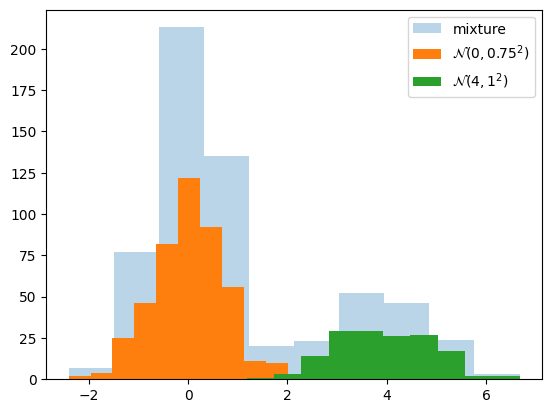

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline


np.random.seed(10)
n1 = np.random.normal(0, 0.75, size=(450, 1))
n2 = np.random.normal(4, 1, size=(150, 1))
X2 = np.vstack([n1, n2]).flatten()

plt.hist(X2, label="mixture", alpha=0.3)
plt.hist(n1, label=r"$\mathcal{N}(0, 0.75^2)$")
plt.hist(n2, label=r"$\mathcal{N}(4, 1^2)$")
plt.legend()
plt.show()

Запустим алгоритм, сравним найденные параметры с параметрами генерации и отрисуем результат.

Слева - динамика log-правдоподобия, справа - гистограммы объектов с назначенными метками. Метку выбираем по максимальной апостериорной вероятности, то есть с учётом и плотности, и веса компоненты $\pi_n$.

Компонента 0: N(mu=3.90, sigma=0.97), π=0.25
Компонента 1: N(mu=0.02, sigma=0.70), π=0.75


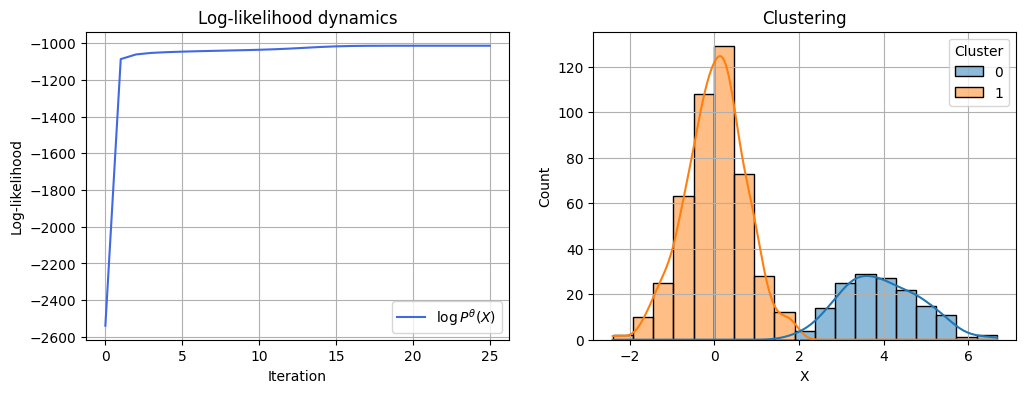

In [ ]:
import pandas as pd
import seaborn as sns


def draw_em_results(X, n_clusters, **kwargs):
    theta, losses = EM(X, n_clusters, **kwargs)
    mus, sigmas, pis = theta
    for n in range(n_clusters):
        print(f"Компонента {n}: N(mu={mus[n]:.2f}, sigma={sigmas[n]:.2f}), π={pis[n]:.2f}")

    fig, axes = plt.subplots(ncols=2, figsize=(12, 4))

    axes[0].plot(losses, label=r'$\log P^\theta(X)$', c='royalblue')
    axes[0].set_xlabel("Iteration")
    axes[0].set_ylabel("Log-likelihood")
    axes[0].legend()
    axes[0].set_title("Log-likelihood dynamics")
    axes[0].grid()

    comp_probs = np.array([
        compute_pn(X, mus[n], sigmas[n] ** 2, pis[n])
        for n in range(n_clusters)
    ])
    y = np.argmax(comp_probs, axis=0)
    df = pd.DataFrame({"X": X, "Cluster": y})
    sns.histplot(df, x="X", hue="Cluster", palette="tab10", ax=axes[1], kde=True)
    axes[1].grid()
    axes[1].set_title("Clustering")

    plt.show()


draw_em_results(X2, 2)

### Четыре компоненты

Теперь увеличим число компонент до четырёх. Остались ли оценки средних, стандартных отклонений и весов близки к параметрам, с которыми мы сгенерировали данные? Номера найденных компонент могут идти в другом порядке.

Для этого примера увеличим предел числа итераций до 500.

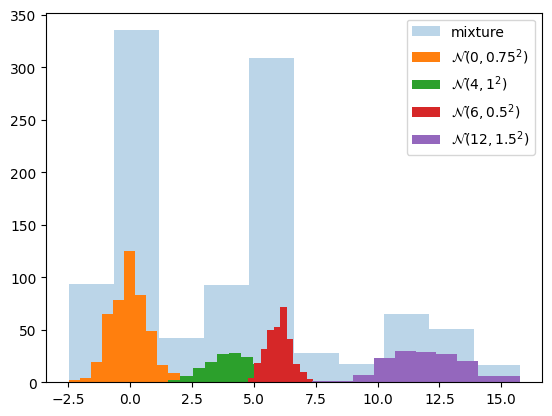

In [ ]:
n1 = np.random.normal(0, 0.75, size=(450, 1))
n2 = np.random.normal(4, 1, size=(150, 1))
n3 = np.random.normal(6, 0.5, size=(300, 1))
n4 = np.random.normal(12, 1.5, size=(150, 1))
X4 = np.vstack([n1, n2, n3, n4]).flatten()

plt.hist(X4, label="mixture", alpha=0.3)
plt.hist(n1, label=r"$\mathcal{N}(0, 0.75^2)$")
plt.hist(n2, label=r"$\mathcal{N}(4, 1^2)$")
plt.hist(n3, label=r"$\mathcal{N}(6, 0.5^2)$")
plt.hist(n4, label=r"$\mathcal{N}(12, 1.5^2)$")
plt.legend()
plt.show()

Компонента 0: N(mu=4.10, sigma=1.01), π=0.14
Компонента 1: N(mu=5.99, sigma=0.51), π=0.29
Компонента 2: N(mu=-0.04, sigma=0.72), π=0.43
Компонента 3: N(mu=12.01, sigma=1.45), π=0.14


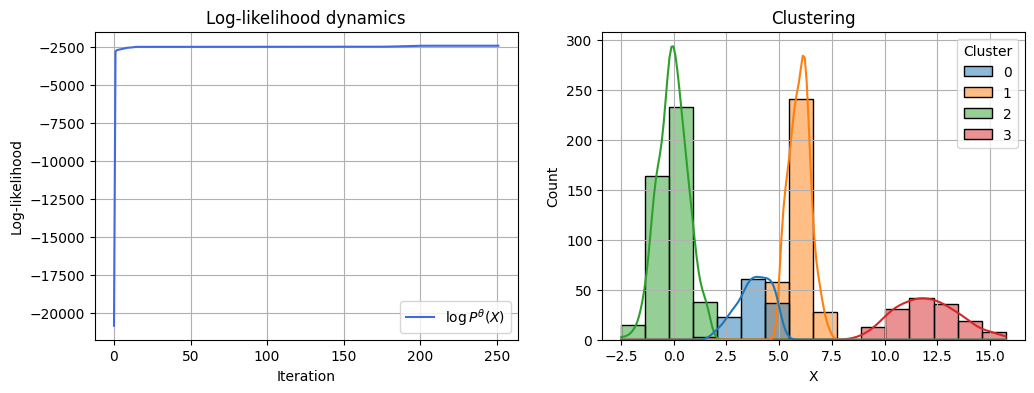

In [ ]:
draw_em_results(X4, 4, max_iter=500)

### Одинаковые средние, разные дисперсии

У обеих компонент среднее равно нулю, но стандартные отклонения различаются: 0.5 и 3. Правило выбора ближайшего среднего здесь не различает компоненты. Посмотрим, как их разделяет EM.

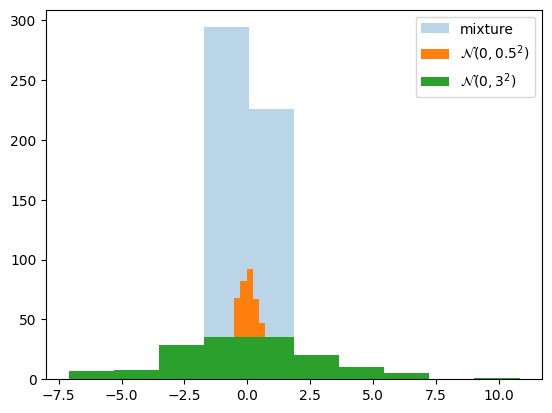

In [ ]:
n1 = np.random.normal(0, 0.5, size=(450, 1))
n2 = np.random.normal(0, 3, size=(150, 1))
X2_2 = np.vstack([n1, n2]).flatten()

plt.hist(X2_2, label="mixture", alpha=0.3)
plt.hist(n1, label=r"$\mathcal{N}(0, 0.5^2)$")
plt.hist(n2, label=r"$\mathcal{N}(0, 3^2)$")
plt.legend()
plt.show()

Компонента 0: N(mu=-0.03, sigma=0.51), π=0.76
Компонента 1: N(mu=-0.06, sigma=3.15), π=0.24


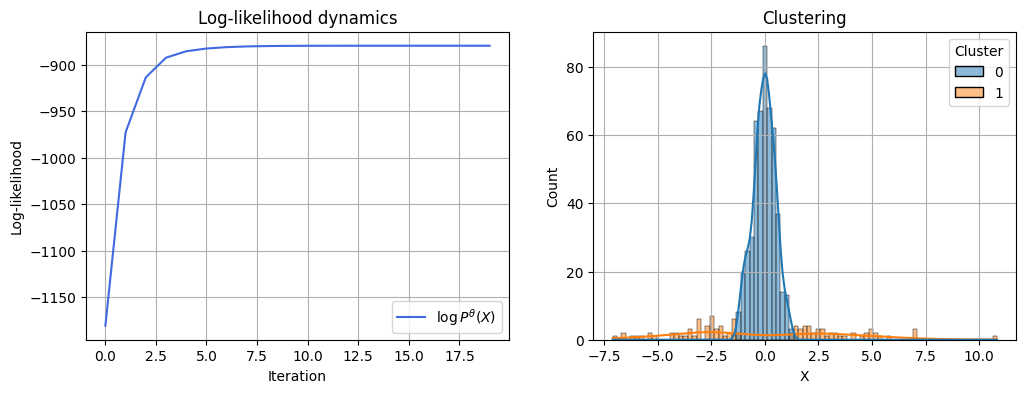

In [ ]:
draw_em_results(X2_2, 2)

### Перекрывающиеся компоненты

Теперь средние близки относительно стандартных отклонений. Сравним найденные параметры с исходными и посмотрим, насколько однозначно можно разделить такие данные.

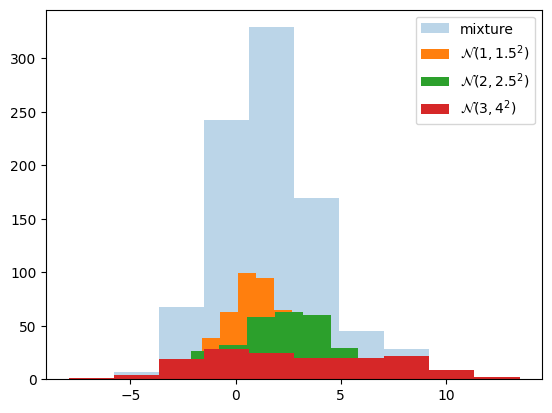

In [ ]:
n1 = np.random.normal(1, 1.5, size=(450, 1))
n2 = np.random.normal(2, 2.5, size=(300, 1))
n3 = np.random.normal(3, 4, size=(150, 1))
X3_2 = np.vstack([n1, n2, n3]).flatten()

plt.hist(X3_2, label="mixture", alpha=0.3)
plt.hist(n1, label=r"$\mathcal{N}(1, 1.5^2)$")
plt.hist(n2, label=r"$\mathcal{N}(2, 2.5^2)$")
plt.hist(n3, label=r"$\mathcal{N}(3, 4^2)$")
plt.legend()
plt.show()

Компонента 0: N(mu=3.57, sigma=3.69), π=0.22
Компонента 1: N(mu=0.99, sigma=0.41), π=0.05
Компонента 2: N(mu=1.14, sigma=2.00), π=0.73


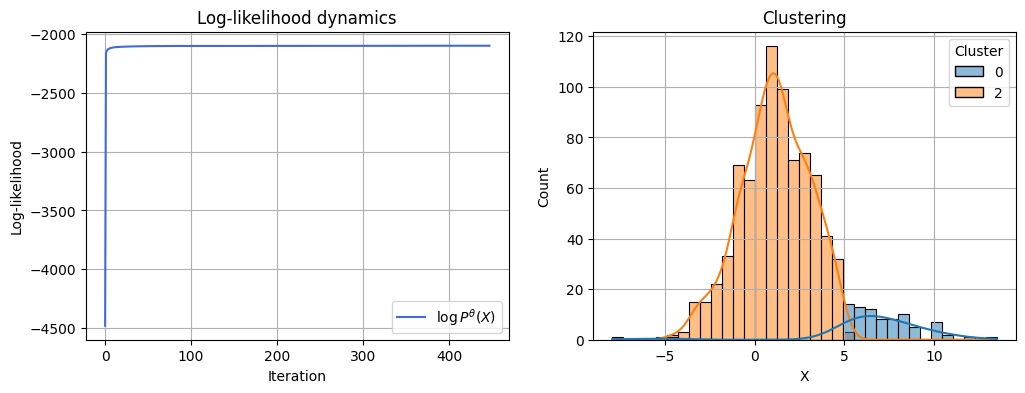

In [ ]:
draw_em_results(X3_2, 3, max_iter=500)

При сильном перекрытии восстановить исходные метки без ошибок нельзя даже при известных параметрах смеси. EM оценивает вероятности принадлежности компонентам, а на графике для каждого объекта мы выбираем только одну метку. Кроме того, результат зависит от начального приближения: мы не можем гарантировать, что найден глобальный максимум.

В последнем примере одна из трёх компонент не получила ни одной метки на графике. Её вес при этом положителен: при обновлении параметров каждый объект вносит в компоненту дробный вклад, а на графике мы выбираем одну наиболее вероятную метку.